# Downloading ICESat-2 data with icepyx

*Section 12 — Downloading data, notebook 8 of 8.* Previous: `07_planet_psscene`. Next: `13_case_study_wetland_mapping/01_composite_and_endmembers`.

**You will learn:**

- how to read regions of interest, their names and bounding boxes from a vector layer with `rsgispy.vector`
- how to map the regions with `rsgispy.mapping.vector.create_vec_lyr_map`
- how to search for, order and download ICESat-2 ATL03 granules for each region with `icepyx`

**Before you start:** the `icepyx` package (`pip install icepyx` or conda-forge; it is not an rsgispy dependency) and a NASA Earthdata Login account (https://urs.earthdata.nasa.gov). Store the Earthdata username and password in an encoded credentials file (`earthdata_userinfo.txt`, see *Earthdata login* below). The maps in section 2 run without an account.

**Data:** downloaded from NASA's NSIDC DAAC (through `icepyx`); the regions of interest are read from `../data/is2_bathy/is2_dwnld_rois.geojson` into `outputs/`.

**Run time:** depends on the download; the search cells take about 1 minute per region and year (the ordering and download take longer).

> **Running this notebook:** every cell that logs in, queries the remote
> service or downloads data is tagged `skip-execution`, so the tutorial test
> runner does not run them. Run them yourself, in order, once you have an
> account and have created the credentials file.

Using the icepyx (https://icepyx.readthedocs.io) Python module, we can easily
download ICESat-2 ATL03 (geolocated photon) data. The data downloaded here
(`outputs/icesat2_dwnld/<roi name>/<year>/*.h5`) are the input to the C-SHELPh
bathymetry notebook, `10_case_study_icesat2_bathymetry/05_cshelph_bathymetry`.

## 1. Import modules

In [1]:
import os

import geopandas
import matplotlib.pyplot as plt

import rsgispy.mapping.vector
import rsgispy.tools.credentials
import rsgispy.tools.geometry
import rsgispy.vector.attrs
import rsgispy.vector.geoms
import rsgispy.vector.io

%matplotlib inline

In [ ]:
# icepyx is an external package (not an rsgispy dependency); install it to
# run the download.
import icepyx

## 2. Get the list of regions of interest

A set of regions of interest (ROIs) has been defined within the vector layer
(`is2_dwnld_rois.geojson`) as polygons using the WGS84 coordinate system
(EPSG:4326). It is for these regions that ICESat-2 data will be downloaded.

### 2.1 Visualise the input data

In [2]:
vec_roi_file = "../data/is2_bathy/is2_dwnld_rois.geojson"
vec_roi_lyr = "is2_dwnld_rois"

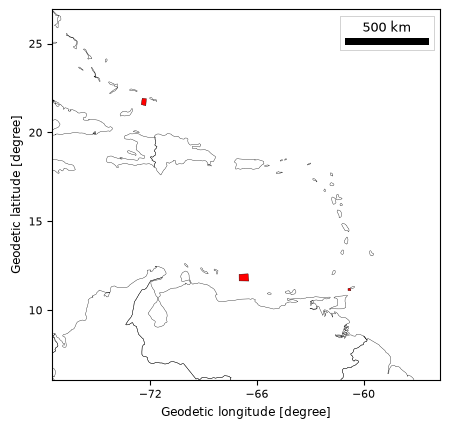

In [3]:
# Define bounding box for map (west, east, south, north) with a 5 degree buffer.
bbox = rsgispy.vector.io.get_vec_lyr_bbox(vec_roi_file, vec_roi_lyr)
bbox = rsgispy.tools.geometry.buffer_bbox(bbox, buf=5)

# Create a plot using the matplotlib library
fig, ax = plt.subplots(figsize=(5, 5))

# Display countries layer to provide background context
countries_df = geopandas.read_file("../data/country.geojson")
_ = rsgispy.mapping.vector.create_vec_lyr_map(ax, countries_df.boundary, bbox)

# Display the ROI file to check where you will be downloading data for.
roi_polys_df = geopandas.read_file(vec_roi_file)
_ = rsgispy.mapping.vector.create_vec_lyr_map(ax, roi_polys_df, bbox, vec_fill_clrs="red")

### 2.2 See the ROI attribute table

Note, the `name` column will be used for the output directory name when we
come to download the data.

In [4]:
roi_polys_df

,name,geometry
0,GranRoque,"POLYGON ((-67.00628 12.01242, -67.00177 11.641..."
1,TurksCicosWest,"POLYGON ((-72.45192 21.9223, -72.22019 21.8937..."
2,NylonPool,"POLYGON ((-60.87687 11.21425, -60.87548 11.095..."


### 2.3 Get the list of names and bounding boxes

In [5]:
names = rsgispy.vector.attrs.read_vec_column(
    vec_file=vec_roi_file, vec_lyr=vec_roi_lyr, att_column="name"
)
# One bounding box (west, east, south, north) per feature.
bboxes = rsgispy.vector.geoms.get_geoms_as_bboxs(vec_file=vec_roi_file, vec_lyr=vec_roi_lyr)
for name, roi_bbox in zip(names, bboxes):
    print(f"{name}: {roi_bbox}")

GranRoque: BBox(west=-67.00628045831778, east=-66.45463951020474, south=11.632942944194298, north=12.040364036591505, epsg=4326)
TurksCicosWest: BBox(west=-72.51719599747197, east=-72.22019384878307, south=21.494501732071853, north=21.92229504883501, epsg=4326)
NylonPool: BBox(west=-60.876873408658966, east=-60.711727735282956, south=11.087004638844185, north=11.225727004480037, epsg=4326)


## 3. Earthdata login

icepyx uses the [earthaccess](https://earthaccess.readthedocs.io) package to
log in to NASA Earthdata, which reads the `EARTHDATA_USERNAME` and
`EARTHDATA_PASSWORD` environment variables (or a `~/.netrc` file). Rather than
writing your username and password into the notebook, create an encoded
credentials file with the `rsgisuserpassfile` command-line tool (installed
with rsgispy; it prompts for the password):

`rsgisuserpassfile -o earthdata_userinfo.txt -u <your Earthdata username>`

and the cell below reads it and sets the environment variables for this
Python session only. The encoding (base64) is **not** secure: keep the file
private and never commit it to version control.

In [ ]:
username, password = rsgispy.tools.credentials.get_username_password(
    input_file="earthdata_userinfo.txt"
)
os.environ["EARTHDATA_USERNAME"] = username
os.environ["EARTHDATA_PASSWORD"] = password

## 4. Download ICESat-2 data

The next block of code iterates through the sites defined within the ROIs
vector layer, creates a set of directories for the data to be downloaded to
and then runs the download — this could take a while depending on your
internet connection. It requires an Earthdata login
(https://www.earthdata.nasa.gov).

Note, the icepyx ordering and download API has changed between icepyx
versions; if `order_granules` / `download_granules` are not available in your
version, check the icepyx documentation for the current equivalent.

In [6]:
# Define the base directory where data will be downloaded to.
base_data_dir = os.path.join("outputs", "icesat2_dwnld")
os.makedirs(base_data_dir, exist_ok=True)

In [ ]:
for name, bbox in zip(names, bboxes):
    print(f"{name}: {bbox}")

    # Query BBOX: [lon_LL, lat_LL, lon_UR, lat_UR]
    query_bbox = [bbox[0], bbox[2], bbox[1], bbox[3]]

    # Define the directory for this ROI
    roi_data_dir = os.path.join(base_data_dir, name)
    os.makedirs(roi_data_dir, exist_ok=True)

    # Loop through the years you want to download
    for year in [2019, 2020]:
        print(f"\t{year}")
        out_data_dir = os.path.join(roi_data_dir, f"{year}")
        os.makedirs(out_data_dir, exist_ok=True)

        # Run Query to find data for the query_bbox and time period
        roi_query = icepyx.Query("ATL03", query_bbox, [f"{year}-01-01", f"{year}-12-31"])

        print("\t\t", roi_query.avail_granules())

        # Order the ICESat-2 Granules:
        roi_query.order_granules()
        # Download the ICESat-2 Granules to out_data_dir
        roi_query.download_granules(out_data_dir)